In [78]:
import xarray as xr
import matplotlib.pyplot as plt 
import cartopy.crs as ccrs
import geopandas as gpd
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm, Normalize
import cmcrameri.cm as cmc
import seaborn as sns
from tqdm.notebook import tqdm

# Helpers

In [ ]:
plt.style.use('robin')
proj = ccrs.NorthPolarStereo(0,70)

def sigmoid(x):
    return 1/(1+np.exp(-x))
def logit(x):
    return np.log(x/(1-x)) 

inch_to_cm = 2.54

ds_regions = xr.open_dataarray('/Data/skd/projects/global/cmip6_precursors/aux/ERA5_rainfall_regions.nc')
ds_regions = ds_regions.where(ds_regions==14, drop=True).sel(lon=slice(0,None))


In [4]:
def add_grid_coastlines(ax, coastline_color='.4', grid_color = '.7'):
    ax.coastlines(color=coastline_color, lw=.5)
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,       # add tick labels
        linewidth=0.4,
        linestyle="-",
        alpha=0.5,
        zorder=2,
        color=grid_color
    )

# Load data

In [8]:
ds_features = xr.open_zarr("/Data/gfi/users/rogui7909/data/ERA5/dynamical_variables/dl_inputs_day_100km_1940-2024_NPS_v2.zarr").load()

run_id ='h82d4u1m'
ds_predictions = xr.open_dataset(f'/Data/gfi/users/rogui7909/data/NN_outputs/attributions/newproj/{run_id}_model_skill.nc').sortby('time')
ds_attrs = xr.open_dataset(f'/Data/gfi/users/rogui7909/data/NN_outputs/attributions/newproj/{run_id}_ALL_attributions_v3_lrpzplus.nc').transpose('y','x',...)
lrp_normed = ds_attrs.attributions_lrp.sum('var_name')/ds_attrs.attributions_lrp.sum('var_name').clip(0).sum(['x','y'])
lrp_normed_vars = ds_attrs.attributions_lrp/ds_attrs.attributions_lrp.sum('var_name').clip(0).sum(['x','y'])
ds_attrs['lrp_normed'] = lrp_normed

gdf_cyclones = gpd.read_file(f'/Data/gfi/users/rogui7909/data/NN_outputs/attributions/newproj/{run_id}_cyclones_data_revised_segmentation_thresh0.001_buffer500_v2_zplus_rolling1.geojson')

gdf_cyclones = gdf_cyclones.set_crs(proj, allow_override=True)
all_cyclones = gpd.read_file('/Data/gfi/users/rogui7909/data/NN_outputs/attributions/newproj/all_cyclones.geojson')
all_cyclones = all_cyclones.set_crs(proj, allow_override=True)



# Figures
## Figure 1: example of input maps

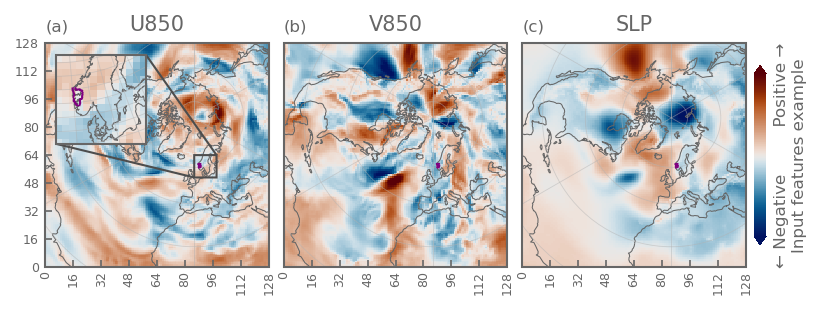

In [30]:
data=((ds_features[['u850','v850','msl']].sel(time='2016-08-05').to_array('var_name')-ds_features.data_mean)/ds_features.data_std)
plot = data.plot(col='var_name',  
                 transform=proj,
                 subplot_kws=dict(projection=proj), vmax=3,
                 aspect=.8, size=2, rasterized=True, 
                 cbar_kwargs=dict(extend='both', shrink=.7, pad=.01, aspect=15),
                 cmap = cmc.vik)
for k,ax in enumerate(plot.axs.flatten()):
    add_grid_coastlines(ax)
    ax.set_extent([-1e7,5e6, -1e7, 5e6], crs=proj)
    ax.set_title(f'Prediction at D{-6+k}', size=8)
    ds_regions.fillna(0).plot.contourf(colors='C4', levels=[13,15], add_colorbar=False,ax=ax, transform=ccrs.PlateCarree())
    ds_regions.fillna(0).plot.contour(colors='purple', levels=[13], 
                                 add_colorbar=False,
                                 ax=ax, 
                                 transform=ccrs.PlateCarree(), 
                                 zorder=200,
                                 linewidths=1)
    if k ==0:
        axins = ax.inset_axes(
            [0.05, 0.55, 0.4, 0.4],
            projection=proj,
            zorder=100)
        data.isel(var_name=k).plot(ax=axins, add_colorbar=False, cmap=cmc.vik_r, vmax=3, rasterized=True)
        axins.set(xlim=(0, 1.5e6), ylim=(-4e6, -2.5e6), xticklabels=[], yticklabels=[])
        add_grid_coastlines(axins)
        ax.indicate_inset_zoom(axins, edgecolor=".3", linewidth=1, alpha=1)
        ds_regions.fillna(0).plot.contour(colors='purple', levels=[13], 
                                 ax=axins, 
                                 transform=ccrs.PlateCarree(), 
                                 zorder=200,
                                 linewidths=1)
        axins.set_title('')
    
    ax.set_xticks(np.linspace(-1e7, 5e6, 9))
    ax.set_xticklabels(np.arange(0, 129, 16), rotation=90, size=6,)
    ax.xaxis.set_tick_params(pad=2)
    ax.set_xlabel('')

ax=plot.axs.flat[0]
ax.set_yticks(np.linspace(-1e7, 5e6, 9))
ax.set_yticklabels(np.arange(0, 129, 16), size=6,)
ax.yaxis.set_tick_params(pad=3)
ax.set_ylabel('')
plot.axs.flat[0].set_title('U850')
plot.axs.flat[1].set_title('V850')
plot.axs.flat[2].set_title('SLP')
plot.cbar.ax.set_yticks([])
plot.cbar.ax.set_ylabel('← Negative         Positive →\nInput features example') 

plot.axs.flat[0].text(0,1.04,'(a)', transform=plot.axs.flat[0].transAxes, va='bottom', ha='left', weight='normal')
plot.axs.flat[1].text(0,1.04,'(b)', transform=plot.axs.flat[1].transAxes, va='bottom', ha='left', weight='normal')
plot.axs.flat[2].text(0,1.04,'(c)', transform=plot.axs.flat[2].transAxes, va='bottom', ha='left', weight='normal')


for mappable in [plot]:
    if hasattr(mappable, 'colorbar') and mappable.colorbar:
        mappable.colorbar.outline.set_visible(False)
cax = mappable.cbar.ax.tick_params
for spine in plot.cbar.ax.spines.values():
    spine.set_visible(False)

plt.savefig('../paper/plots/pdf_revisions/fig01.pdf', bbox_inches='tight')

# plt.savefig('../paper/plots/svg/fig01.svg', bbox_inches='tight')



## Figure 3: example of relevance maps

In [31]:
def find_top_cyc(df):
    return df.iloc[df.patch_attributions.argmax()]

top_cycs_data = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(
    find_top_cyc
)

/tmp/ipykernel_1711940/227351796.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_cycs_data = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(


/tmp/ipykernel_1711940/4150779880.py:36: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_extract = top_cycs_data.query(f"time_of_event=='{time_of_event_list[k]}' & timestep_past=={timestep_past_list[k]}")#.plot(ax=map_axs[1,0], edgecolor='1', color='none', alpha=.7, zorder=100, transform=proj, markersize=5)
/tmp/ipykernel_1711940/4150779880.py:36: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_extract = top_cycs_data.query(f"time_of_event=='{time_of_event_list[k]}' & timestep_past=={timestep_past_list[k]}")#.plot(ax=map_axs[1,0], edgecolor='1', color='none', alpha=.7, zorder

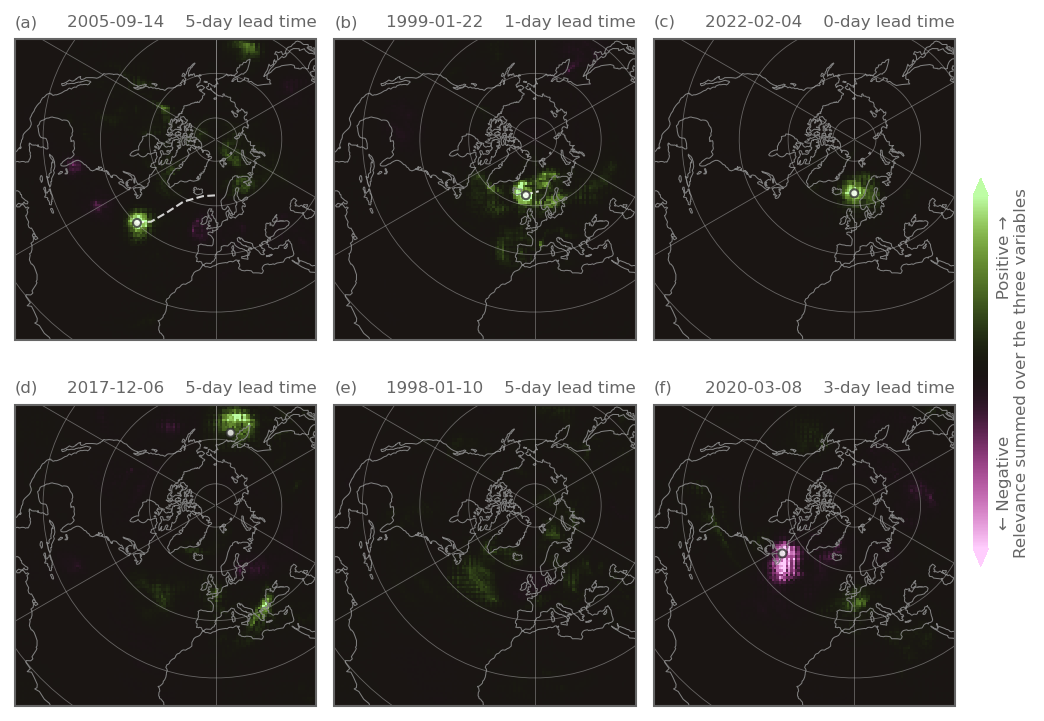

In [64]:
fig, axs = plt.subplot_mosaic("""
                              ABC.
                              ABCc
                              ABCc
                              DEFc
                              DEFc
                              DEF.
                              """,
                              figsize=(7,5), 
                            per_subplot_kw={
                                'A': dict(projection=proj),
                                'B': dict(projection=proj),
                                'C': dict(projection=proj),
                                'D': dict(projection=proj),
                                'E': dict(projection=proj),
                                'F': dict(projection=proj),
                                'c': {}  
                            },
                                  gridspec_kw=dict(
                                width_ratios=[1, 1,1, 0.05],
                                  )
                              )
                              


map_axs = np.array([[axs['A'], axs['B'], axs['C']], [axs['D'], axs['E'], axs['F']]])
for k,ax in enumerate(map_axs.flat):
    add_grid_coastlines(ax, coastline_color='.5')
    ax.set_title('')
    ax.set_title('('+chr(ord('a') + k)+')', size=8, loc='left', weight='normal')
time_of_event_list = ['2005-09-14', '1999-01-22', '2022-02-04']
timestep_past_list = [-5, -1, 0]
vmax_list = [0.003,  0.003, 0.008]
for k in range(3):
    ds_attrs.sel(time_of_event = time_of_event_list[k], timestep_past = timestep_past_list[k]).lrp_normed.plot(ax=map_axs[0,k], cmap=cmc.vanimo, transform=proj, rasterized=True, vmax=vmax_list[k], cbar_ax=axs['c'], cbar_kwargs=dict(extend='both', shrink=.5, pad=.01, aspect=10))
    df_extract = top_cycs_data.query(f"time_of_event=='{time_of_event_list[k]}' & timestep_past=={timestep_past_list[k]}")#.plot(ax=map_axs[1,0], edgecolor='1', color='none', alpha=.7, zorder=100, transform=proj, markersize=5)
    cyc = df_extract.set_geometry(gpd.points_from_xy(df_extract.cyclone_x, df_extract.cyclone_y))
    track_id = cyc.cyclone_track_id.values[0]
    cyc_traj = all_cyclones.query("track_id==@track_id").set_index('date').loc[:time_of_event_list[k]][timestep_past_list[k]-1:]
    map_axs[0,k].plot(cyc_traj.x, cyc_traj.y,  zorder=200, transform=proj, alpha=.8, color='1', lw=1,ls='--')
    cyc.buffer(200000).plot(ax=map_axs[0,k], edgecolor='.2', color='1', alpha=.8, zorder=300, transform=proj, )
    map_axs[0,k].set_title(f"", size=8, loc='center', weight='normal')
    map_axs[0,k].set_title(time_of_event_list[k]+'    ' +f"{-timestep_past_list[k]}-day lead time", size=8, loc='right', weight='normal')


# 2017-12-06 -5 # pacific
# 1998-01-10 -5 # weak overall
# 2020-03-08 -3 # negative cyclones
# 2015-02-19 -3 # biggest not a cyclone

time_of_event_list_fail = ['2017-12-06','1998-01-10','2020-03-08']
timestep_past_list_fail = [-5, -5, -3, -3]
vmax_list_fail = [0.003, 0.003, 0.006, 0.008]


for k in range(3):
    ds_attrs.sel(time_of_event = time_of_event_list_fail[k], timestep_past = timestep_past_list_fail[k]).lrp_normed.plot(ax=map_axs[1,k], cmap=cmc.vanimo, transform=proj, add_colorbar=False, rasterized=True, vmax=vmax_list_fail[k])
    
    if k in [0]:
        df_extract = top_cycs_data.query(f"time_of_event=='{time_of_event_list_fail[k]}' & timestep_past=={timestep_past_list_fail[k]}")#.plot(ax=map_axs[1,0], edgecolor='1', color='none', alpha=.7, zorder=100, transform=proj, markersize=5)
        cyc = df_extract.set_geometry(gpd.points_from_xy(df_extract.cyclone_x, df_extract.cyclone_y))
    elif k in [2]:
        df_extract =gdf_cyclones.query("time_of_event=='2020-03-08' & timestep_past==-3").sort_values('patch_attributions').iloc[[0]]
        cyc = df_extract.set_geometry(gpd.points_from_xy(df_extract.cyclone_x, df_extract.cyclone_y))
    if k in [0,2]:
        cyc.buffer(200000).plot(ax=map_axs[1,k], edgecolor='.2', color='1', alpha=.8, zorder=300, transform=proj, )

    map_axs[1,k].set_title(f"", size=8, loc='center', weight='normal')
    map_axs[1,k].set_title(time_of_event_list_fail[k]+'    ' +f"{-timestep_past_list_fail[k]}-day lead time", size=8, loc='right', weight='normal')


for spine in axs['c'].spines.values():
    spine.set_visible(False)
axs['c'].tick_params(left=False, right=False, labelleft=False, labelright=False, labelbottom=False, labeltop=False)
axs['c'].set_ylabel('← Negative                          Positive →\nRelevance summed over the three variables', size=8, loc='center', weight='normal')

plt.tight_layout()
plt.savefig('../paper/plots/pdf_revisions/fig03.pdf', bbox_inches='tight')


## Figure 5: neural network skill

In [61]:
persistance = xr.ones_like(ds_predictions.targets).where(ds_predictions.targets.isel(timestep=0)==1).fillna(0)
climatology = (ds_predictions.where(ds_predictions.dataset=='test').targets==1).sum('time')/(ds_predictions.where(ds_predictions.dataset=='test').targets>=0).sum('time')
climatology = climatology.isel(timestep=0).values

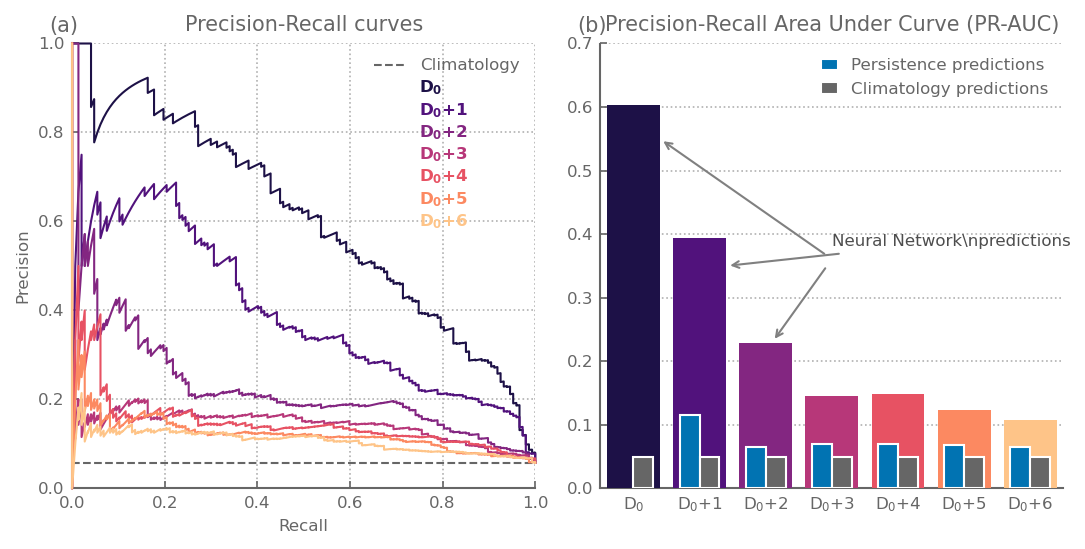

In [73]:
fig, axs = plt.subplots(1,2, figsize=(7.5,3.7))

from sklearn.metrics import precision_recall_curve, average_precision_score
colors = sns.color_palette('magma', n_colors=7)
for k in range(7):
    precision, recall, _ = precision_recall_curve(ds_predictions.sel(timestep=k).targets.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True),
                                                ds_predictions.sel(timestep=k).predictions.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True))
    axs[0].plot(recall, precision, label=None, lw=1, clip_on=False, zorder=100, color=colors[k])

list_labels =[r'D$_0\plus$'+f'{k}' if k >0 else f'D$_0$' for k in range(7)]
for k in range(7):
    axs[0].text(0.75, 0.90-k*0.05, list_labels[k], transform=axs[0].transAxes, color=colors[k], fontsize=8,  va='center', zorder=200, weight='bold', ha='left') 

# axs[0].plot([0,1,1],[1,1,0], label='Perfect\nclassifier', color='C2', lw=1, clip_on=False, zorder=100, ls='dashdot')
axs[0].axhline(climatology, label='Climatology', color='.4', linestyle='--')


axs[0].set(xlim = (0,1,), ylim=(0,1))
axs[0].grid()
axs[0].legend(handlelength=2, loc='upper right')
axs[0].set_title('Precision-Recall curves', size=10)
axs[0].set_xlabel('Recall')
axs[0].set_ylabel('Precision')

from sklearn.metrics import average_precision_score
prauc_nn = np.array([average_precision_score(ds_predictions.sel(timestep=k).targets.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True),
                        ds_predictions.sel(timestep=k).predictions.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True)) for k in range(7)])
# axs[1].plot(np.arange(0,7,1),prauc_nn , label='Neural Network predictions', marker='o', markersize=4, color='C2', clip_on=False, zorder=100, lw=1.5)
prauc_persistence = np.array([average_precision_score(ds_predictions.sel(timestep=k).targets.where(ds_predictions.sel(timestep=k).dataset=='test', drop=True),
                        persistance.sel(timestep=k).where(ds_predictions.dataset=='test', drop=True)) for k in range(1,7)],)

axs[1].bar( np.arange(0,7,1),prauc_nn ,  clip_on=False, zorder=100, color=colors, width=.8)
axs[1].bar( np.arange(1,7,1)-.15,prauc_persistence , label='Persistence predictions',  clip_on=True, zorder=100, color='C0', width=.3, edgecolor='1')
axs[1].bar( np.arange(0,7,1)+.15,prauc_nn-prauc_nn+0.05 , label='Climatology predictions',  clip_on=True, zorder=100, color='.4', width=.3, edgecolor='1')


# axs[1].scatter(np.arange(1,7,1),prauc_persistence, label='Predictions based on persistence', clip_on=False, marker='s', s=4, color='C0', zorder=100, lw=1)
# axs[1].axhline(0.05, label='Predictions based on climatology', color='.3', linestyle='--')

axs[1].set_xticks(np.arange(0,7))
axs[1].set_xticklabels(['D$_0$']+[r"D$_0\plus$"+f"{t}" for t in range(1,7)] )


axs[1].legend(frameon=True, framealpha=1, edgecolor='1')
axs[1].set_ylim(0,0.7)
axs[1].grid(zorder=200, axis='y')
axs[1].set_xlim(-.5,6.5)
axs[1].set_title('Precision-Recall Area Under Curve (PR-AUC)')
# axs[1].set_xlabel('Predicted day (from D$_0$)')
axs[1].annotate(r'Neural Network\npredictions', xy=(1.4, 0.35),xytext=(3, 0.4), arrowprops=dict(arrowstyle='->', color='.5'), 
                color='.3', fontsize=8,  va='top', zorder=200, weight='normal', ha='left')
axs[1].annotate('\n\n', xy=(0.4, 0.55),xytext=(3, 0.4), arrowprops=dict(arrowstyle='->', color='.5'), 
                color='.3', fontsize=8,  va='top', zorder=200, weight='normal', ha='left')
axs[1].annotate('\n\n', xy=(2.1, 0.23),xytext=(3, 0.4), arrowprops=dict(arrowstyle='->', color='.5'), 
                color='.3', fontsize=8,  va='top', zorder=200, weight='normal', ha='left')

axs[0].text(-.05, 1.04,'(a)', transform=axs[0].transAxes, va='center', ha='left', weight='normal', size=10)
axs[1].text(-0.05, 1.04,'(b)', transform=axs[1].transAxes, va='center', ha='left', weight='normal', size=10)

plt.tight_layout()

plt.savefig('../paper/plots/pdf_revisions/fig05.pdf', bbox_inches='tight')


## Figure 6: naive averages

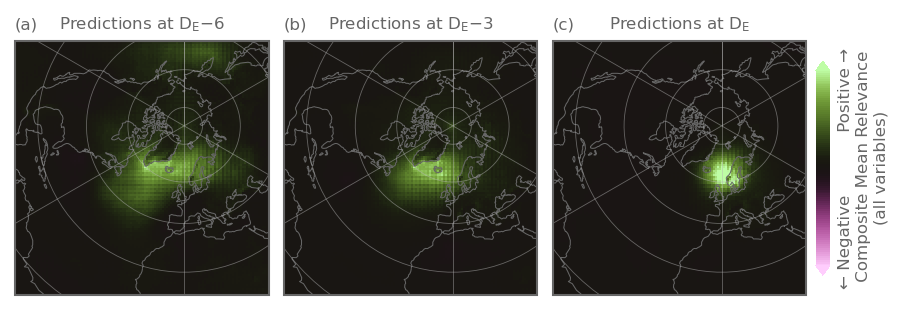

In [74]:
ds_attrs_mean = ds_attrs.lrp_normed.mean('time_of_event')

plot = (ds_attrs_mean/ds_attrs_mean.quantile(.99,['x','y'])).rolling(x=1,y=1,center=True).mean().fillna(0).sel(timestep_past=[-6,-3,0]).plot(col='timestep_past', levels=101,
                                                                                                                                                    transform=proj,
                                                                                                                                                    subplot_kws=dict(projection=proj), vmax=1.5,
                                                                                                                                                    aspect=.8, size=2.3, rasterized=True, 
                                                                                                                                                    extend='both',
                                                                                                                                                    cbar_kwargs=dict(extend='both', shrink=.7, pad=.01, aspect=15),
                                                                                                                                                    cmap = cmc.vanimo)
for k,ax in enumerate(plot.axs.flatten()):
    add_grid_coastlines(ax)
    ax.set_extent([-1e7,5e6, -1e7, 5e6], crs=proj)
    ax.tick_params(left=False, right=False, labelleft=False, labelright=False)
    ax.set_title('('+chr(ord('a') + k)+')', size=8, loc='left', weight='normal')
plot.axs[0,0].set_title(r'Predictions at D$_\text{E}\minus$6', size=8)
plot.axs[0,1].set_title(r'Predictions at D$_\text{E}\minus$3', size=8)
plot.axs[0,2].set_title(r'Predictions at D$_\text{E}$', size=8)

cax = plot.cbar.ax
for spine in cax.spines.values():
        spine.set_visible(False)

cax.tick_params(right=False, left=False, labelleft=False, labelright=False, which='both')

cax.set_ylabel('← Negative            Positive →\n Composite Mean Relevance\n(all variables)', size=8)

plt.savefig('../paper/plots/pdf_revisions/fig06.pdf', bbox_inches='tight')



## Figure 7: predictions are associated with cyclones

In [79]:
def find_top_cyc(df):
    return df.iloc[df.patch_attributions.argmax()]

top_cycs_data = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(
    find_top_cyc
)

all_top_used_track = []
for time_of_event in tqdm(ds_attrs.time_of_event.values):
    all_used_cyclones = gdf_cyclones.query("is_cyclone or patch_attributions>.1").query("time_of_event==@time_of_event").set_index('timestep_past')#.cyclone_track_id.dropna()
    used_cyclones_at_D0 = all_used_cyclones.loc[[0]].sort_values("patch_attributions", ascending=False)#.cyclone_track_id.dropna().values
    if used_cyclones_at_D0.size ==0:
        print('empty')
        continue
        
    main_cyclone_D0 = used_cyclones_at_D0.iloc[0]
    if main_cyclone_D0.patch_attributions<0.1:
        print('Weak attribution')
        continue
        
    main_cyclone_D0_ID = main_cyclone_D0.cyclone_track_id
    main_cyclone_D0_track = all_cyclones.query("track_id==@main_cyclone_D0_ID").set_index('date').loc[:time_of_event].reset_index()
    main_cyclone_D0_track_used = all_used_cyclones.query("cyclone_track_id==@main_cyclone_D0_ID")
    main_used_cyclones = all_used_cyclones.groupby('timestep_past').apply(find_top_cyc)

    main_used_cyclones_is_main_D0_cyclone = (main_used_cyclones.cyclone_track_id ==main_cyclone_D0_ID)

    new_time = pd.date_range(time_of_event+pd.Timedelta('-6D'), time_of_event, freq='D')
    main_cyclone_D0_exists = main_cyclone_D0_track.set_index('date').reindex(new_time).reset_index().track_id.notnull()
    main_cyclone_D0_used_above_10percent = all_used_cyclones.query("cyclone_track_id==@main_cyclone_D0_ID and patch_attributions>0.1").set_index('cyclone_date').reindex(new_time).reset_index().cyclone_track_id.notnull()
    main_cyclone_D0_used_below_10percent = all_used_cyclones.query("cyclone_track_id==@main_cyclone_D0_ID and patch_attributions<0.1").set_index('cyclone_date').reindex(new_time).reset_index().cyclone_track_id.notnull()
    main_cyclone_D0_is_main_cyclone = (main_used_cyclones.cyclone_track_id ==main_cyclone_D0_ID).reindex(np.arange(-6,1)).reset_index(drop=True)
    main_cyclone_D0_is_main_cyclone_and_above_10percent = ((main_used_cyclones.cyclone_track_id ==main_cyclone_D0_ID) & (main_used_cyclones.patch_attributions > 0.1)).reindex(np.arange(-6,1)).reset_index(drop=True)
    there_is_a_10percent_used_cyclone = ((main_used_cyclones.patch_attributions>0.1) &(main_used_cyclones.is_cyclone)).reindex(np.arange(-6,1))>0.1
    patch_attributions_top_cyclone = main_used_cyclones.patch_attributions.reindex(np.arange(-6,1))

    df_out = pd.DataFrame({
        'time_of_event': time_of_event,
        'main_cyclone_D0_exists': main_cyclone_D0_exists.values,
        'main_cyclone_D0_used_above_10percent': main_cyclone_D0_used_above_10percent.values,
        'main_cyclone_D0_used_below_10percent': main_cyclone_D0_used_below_10percent.values,
        'main_cyclone_D0_is_main_cyclone': main_cyclone_D0_is_main_cyclone.values,
        'main_cyclone_D0_is_main_cyclone_and_above_10percent': main_cyclone_D0_is_main_cyclone_and_above_10percent.values,
        'there_is_a_10percent_used_cyclone': there_is_a_10percent_used_cyclone.values,
        'patch_attributions_top_cyclone': patch_attributions_top_cyclone.values,
        'main_cyclone_track_id': main_used_cyclones.cyclone_track_id.reindex(np.arange(-6,1)).values,
        'is_main_patch_cyclone': main_used_cyclones.is_cyclone.reindex(np.arange(-6,1)).values,
        'is_main_patch_cyclone_above10percent': (main_used_cyclones.is_cyclone & (main_used_cyclones.patch_attributions > 0.1)).reindex(np.arange(-6,1)).values,
    },
    index=np.arange(-6,1))
    all_top_used_track.append(df_out)
all_top_used_track = pd.concat(all_top_used_track)

all_top_used_track['D0_cyclone_exists__but_other_cyclone_used'] = (all_top_used_track.main_cyclone_D0_exists) & (all_top_used_track.main_cyclone_D0_is_main_cyclone==False) & (all_top_used_track.there_is_a_10percent_used_cyclone)
all_top_used_track['D0_cyclone_exists__but_no_cyclone_used'] = (all_top_used_track.main_cyclone_D0_exists)  & (all_top_used_track.there_is_a_10percent_used_cyclone==False)
all_top_used_track['D0_cyclone_doesnt_exist__but_cyclones_above10percent'] = (all_top_used_track.main_cyclone_D0_exists == False)  & (all_top_used_track.there_is_a_10percent_used_cyclone)
all_top_used_track['D0_cyclone_doesnt_exist__and_no_cyclones_above10percent'] = (all_top_used_track.main_cyclone_D0_exists == False)  & (all_top_used_track.there_is_a_10percent_used_cyclone==False)


/tmp/ipykernel_1711940/1115764560.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_cycs_data = gdf_cyclones.reset_index().groupby(['time_of_event','timestep_past']).apply(


  0%|          | 0/840 [00:00<?, ?it/s]

Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution
Weak attribution


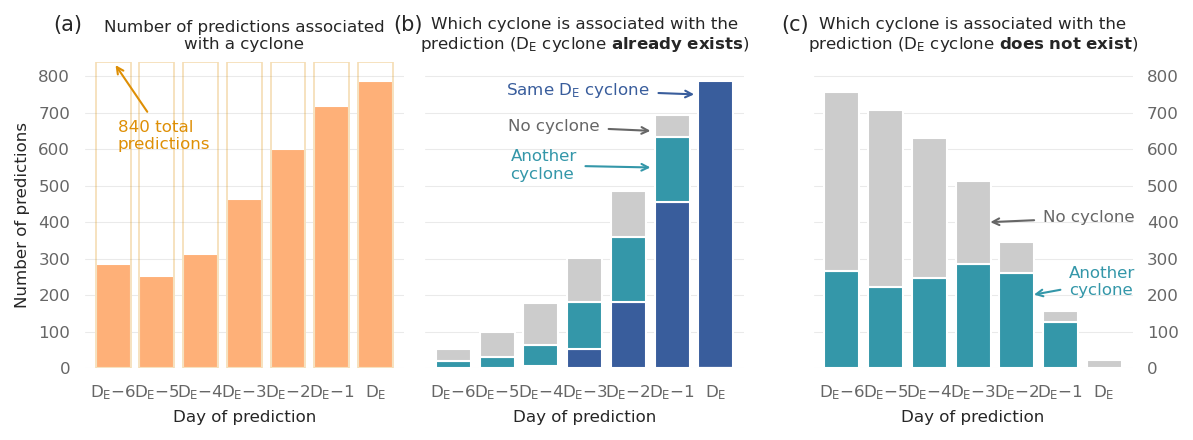

In [99]:
sns.set_style('whitegrid')
fig, axs = plt.subplots(1,3, figsize=(8,3), sharex=True, sharey=True)
df_plot = all_top_used_track.reset_index().groupby('index').sum(numeric_only=True)
df_plot2 = all_top_used_track.query("main_cyclone_D0_exists").reset_index().groupby('index').sum(numeric_only=True)[['main_cyclone_D0_used_above_10percent','D0_cyclone_exists__but_other_cyclone_used','D0_cyclone_exists__but_no_cyclone_used',]]

df_plot[['there_is_a_10percent_used_cyclone']].plot.bar(stacked=True, ax=axs[0], color=[sns.color_palette('magma_r', n_colors=5)[0],(.8,.8,.8)], edgecolor='1', width=.8)

df_plot3=all_top_used_track.query("main_cyclone_D0_exists == False").reset_index().groupby('index').sum(numeric_only=True)[['D0_cyclone_doesnt_exist__but_cyclones_above10percent','D0_cyclone_doesnt_exist__and_no_cyclones_above10percent',]]
df_plot2.plot.bar(stacked=True, ax=axs[1], color=sns.color_palette('mako', n_colors=4)[1:3]  + [(.8,.8,.8)], edgecolor='1', width=.8)
df_plot3.plot.bar(stacked=True, ax=axs[2], color=sns.color_palette('mako', n_colors=4)[2:3]  + [(.8,.8,.8)], edgecolor='1', width=.8)

for ax in axs:
    ax.grid()
    ax.grid(axis='y', linestyle='-', alpha=.4, lw=.5)
    sns.despine(ax=ax, left=True, bottom=True, right=True)
    ax.legend().remove()
    ax.tick_params(rotation=0)
    ax.set_xticks(np.arange(0,7))
    ax.set_xticklabels([r"D$_\text{E}\minus$"+str(-i) if i < 0 else r"D$_\text{E}$"  for i in range(-6,1)])
    ax.set_xlabel("Day of prediction")
    ax.set_ylim(0,840)
    ax.tick_params(left=False,labelleft=True, )

axs[0].bar(np.arange(7),[840 for k in range(7)], color='None',edgecolor='C1', linewidth=.8, alpha=.3)
axs[0].set_title('Number of predictions associated\n'+r'with a cyclone', size=8)
axs[1].set_title('Which cyclone is associated with the\n'+r'prediction (D$_\text{E}$ cyclone $\mathbf{already}$ $\mathbf{exists}$)', size=8)
axs[2].set_title('Which cyclone is associated with the\n'+r'prediction (D$_\text{E}$ cyclone $\mathbf{does}$ $\mathbf{not}$ $\mathbf{exist}$)', size=8)

axs[0].annotate(xy = (0,840), xytext=(.1, 600), text='840 total\npredictions', arrowprops=dict(arrowstyle='->', color='C1'),color='C1' )

colors = sns.color_palette('mako', n_colors=4)[1:3]  + [(.8,.8,.8)]
axs[1].annotate(xy = (5.6,750), xytext=(1.2, 750), text=r'Same D$_\text{E}$ cyclone', arrowprops=dict(arrowstyle='->', color=colors[0]),color=colors[0] )
axs[1].annotate(xy = (4.6,650), xytext=(1.25, 650), text='No cyclone', arrowprops=dict(arrowstyle='->', color='.4'),color='.4' )
axs[1].annotate(xy = (4.6,550), xytext=(1.3, 520), text='Another\ncyclone', arrowprops=dict(arrowstyle='->', color=colors[1]),color=colors[1] )

axs[2].annotate(xytext = (4.6,400), xy=(3.3, 400), text='No cyclone', arrowprops=dict(arrowstyle='->', color='.4'),color='.4' )
axs[2].annotate(xytext = (5.2,200), xy=(4.3, 200), text='Another\ncyclone', arrowprops=dict(arrowstyle='->', color=colors[1]),color=colors[1] )

axs[0].set_ylabel("Number of predictions")

axs[0].text(-.1, 1.1, '(a)', weight='normal', transform=axs[0].transAxes, size=10)
axs[1].text(-.1, 1.1, '(b)', weight='normal', transform=axs[1].transAxes, size=10)
axs[2].text(-.1, 1.1, '(c)', weight='normal', transform=axs[2].transAxes, size=10)


axs[1].tick_params(labelleft=False)
axs[2].tick_params(labelleft=False, labelright=True)
plt.tight_layout()
pos = axs[1].get_position()
axs[1].set_position([pos.x0 - 0.02, pos.y0, pos.width, pos.height])


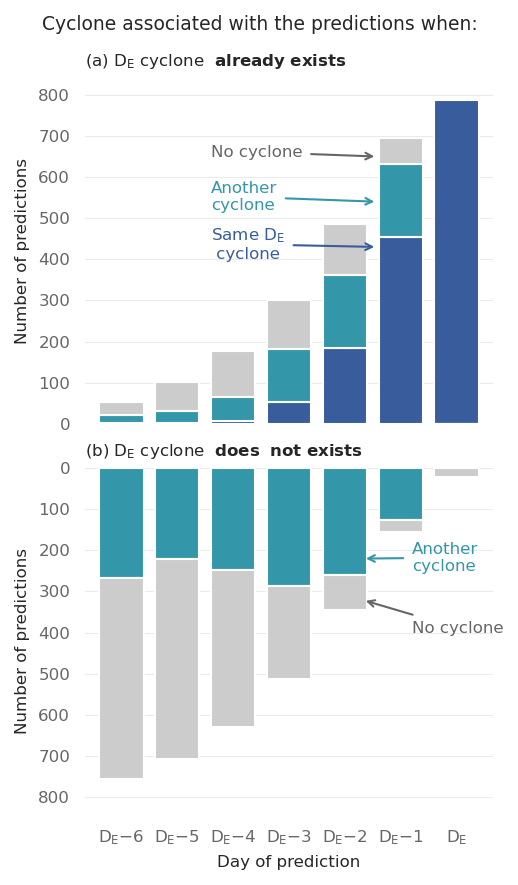

In [171]:
sns.set_style('whitegrid')
fig, axs = plt.subplots(2,1, figsize=(3.5,6), sharex=True )
df_plot = all_top_used_track.reset_index().groupby('index').sum(numeric_only=True)
df_plot2 = all_top_used_track.query("main_cyclone_D0_exists").reset_index().groupby('index').sum(numeric_only=True)[['main_cyclone_D0_used_above_10percent','D0_cyclone_exists__but_other_cyclone_used','D0_cyclone_exists__but_no_cyclone_used',]]

df_plot3=all_top_used_track.query("main_cyclone_D0_exists == False").reset_index().groupby('index').sum(numeric_only=True)[['D0_cyclone_doesnt_exist__but_cyclones_above10percent','D0_cyclone_doesnt_exist__and_no_cyclones_above10percent',]]
df_plot2.plot.bar(stacked=True, ax=axs[0], color=sns.color_palette('mako', n_colors=4)[1:3]  + [(.8,.8,.8)], edgecolor='1', width=.8)
df_plot3.plot.bar(stacked=True, ax=axs[1], color=sns.color_palette('mako', n_colors=4)[2:3]  + [(.8,.8,.8)], edgecolor='1', width=.8)

for ax in axs:
    ax.grid()
    ax.grid(axis='y', linestyle='-', alpha=.4, lw=.5)
    sns.despine(ax=ax, left=True, bottom=True, right=True)
    ax.legend().remove()
    ax.tick_params(rotation=0)
    ax.set_xticks(np.arange(0,7))
    ax.set_xticklabels([r"D$_\text{E}\minus$"+str(-i) if i < 0 else r"D$_\text{E}$"  for i in range(-6,1)])
    ax.set_xlabel("Day of prediction")
    ax.set_ylim(0,840)
    ax.tick_params(left=False,labelleft=True, )
    ax.set_ylabel("Number of predictions")
axs[1].set_ylim(840,0)

axs[0].set_xlabel('')
# axs[0].text(-.5,750,"Cyclone associated with the prediction:")
axs[0].annotate(xy = (4.6,650), xytext=(1.6, 650), text='No cyclone', arrowprops=dict(arrowstyle='->', color='.4'),color='.4' )
axs[0].annotate(xy = (4.6,540), xytext=(1.6, 520), text='Another\ncyclone', arrowprops=dict(arrowstyle='->', color=colors[1]),color=colors[1] )
axs[0].annotate(xy = (4.6,430), xytext=(1.6, 400), text='Same '+r'D$_\text{E}$'+'\n cyclone', arrowprops=dict(arrowstyle='->', color=colors[0]),color=colors[0] )

axs[1].annotate(xytext = (5.2,400), xy=(4.3, 320), text='No cyclone', arrowprops=dict(arrowstyle='->', color='.4'),color='.4' )
axs[1].annotate(xytext = (5.2,250), xy=(4.3, 220), text='Another\ncyclone', arrowprops=dict(arrowstyle='->', color=colors[1]),color=colors[1] )

axs[0].set_title(r'(a) D$_{\text{E}}$ cyclone  $\mathbf{already}$ $\mathbf{exists}$', loc='left', size=8)
axs[1].set_title(r'(b) D$_{\text{E}}$ cyclone  $\mathbf{does}$  $\mathbf{not}$ $\mathbf{exists}$', loc='left', size=8)

fig.suptitle('Cyclone associated with the predictions when:', size=9, weight='normal')
plt.tight_layout()
pos = axs[1].get_position()
axs[1].set_position([pos.x0 , pos.y0+.01, pos.width, pos.height])

plt.savefig('../paper/plots/pdf_revisions/fig07.pdf', bbox_inches='tight')
